# Task 1: Scene Construction

## Setup Code / Packages
Follow the instructions to download MuJoCo and setup your environment [here](../docs/setup.md).


## Import Packages

In [1]:
import mujoco as mj
import mediapy 

In [2]:
def render(xml_path: str, camera_name: str = ""):
    model = mj.MjModel.from_xml_path(xml_path)
    data = mj.MjData(model)
    camera_id = mj.mj_name2id(model, mj.mjtObj.mjOBJ_CAMERA, camera_name)


    with mj.Renderer(model) as renderer:
        mj.mj_forward(model, data)
        renderer.update_scene(data, camera_id)
        image = renderer.render()
        mediapy.show_image(image)

Add the desired objects into the xml file. Fix the camera viewing angle inside of the xml to get a good view of the scene.

""

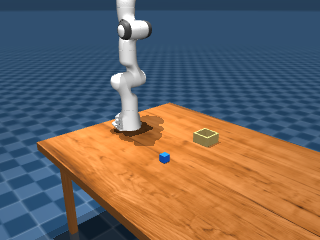

In [3]:
import os

xml_file = os.path.abspath("../assets/descriptions/DropCubeInBinEnv.xml")
render(xml_file, camera_name="fixed")

""

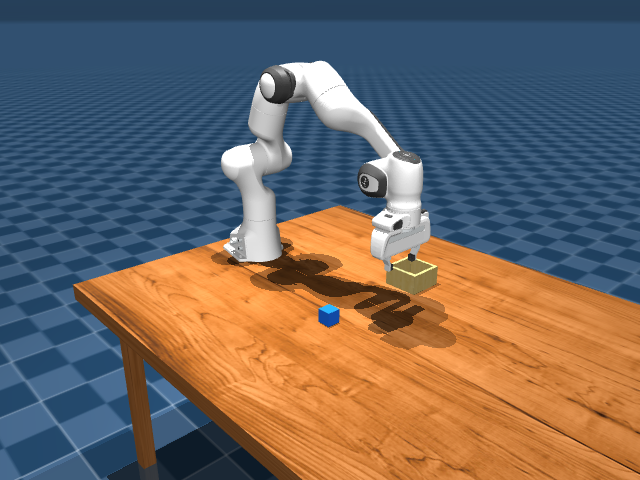

In [4]:
# The render() helper above draws the default joint values (all zeros), so the arm points straight up.
# Here we reset to the "home" keyframe first, which is the robot's actual starting pose.
model = mj.MjModel.from_xml_path(xml_file)
data = mj.MjData(model)
mj.mj_resetDataKeyframe(model, data, model.key("home").id)
mj.mj_forward(model, data)
with mj.Renderer(model, 480, 640) as renderer:
    renderer.update_scene(data, "fixed")
    mediapy.show_image(renderer.render())